## **Tarea 1: Analisis del Titánic**

La finalidad de este análisis es intentar encontrar algún tipo de relación entre las diferentes variables presentes en este dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


#### 1. Información general
El conjunto de datos dispone de información sobre **891** pasajeros del famoso **transatlántico**.
La información puede clasifirse en:
* Información personal
* Datos sobre su billete
* La variable **Survived** que indica si este pasajero sobrevivió(1) o murió (0)

In [25]:
titanic_passengers=pd.read_csv('data/Titanic.csv',index_col=0)


El dataset contiene las siguientes variables


 Columna         | Tipo de dato         | Descripción                                                                |
| --------------- | -------------------- | -------------------------------------------------------------------------- |
| **survived**    | numérica (0 o 1)     | Indica si el pasajero sobrevivió (1) o no (0).                             |
| **pclass**      | categórica (1, 2, 3) | Clase del pasajero (1ª, 2ª o 3ª).                                          |
| **sex**         | categórica           | Sexo del pasajero (*male* o *female*).                                     |
| **age**         | numérica             | Edad del pasajero en años (puede haber valores faltantes).                 |
| **sibsp**       | numérica             | Cantidad de hermanos o cónyuges a bordo.                                   |
| **parch**       | numérica             | Cantidad de padres o hijos a bordo.                                        |
| **fare**        | numérica             | Tarifa pagada por el pasaje (en libras).                                   |
| **cabin**        | texto             | Camarote del pasajero                                   |
| **embarked**    | categórica           | Puerto de embarque (*C = Cherbourg*, *Q = Queenstown*, *S = Southampton*). |
| **class**       | categórica           | Nombre de la clase (1st, 2nd, 3rd) — equivalente a `pclass`.               |




---

In [27]:
titanic_passengers.dtypes

Survived      int64
Pclass        int64
Name            str
Sex             str
Age         float64
SibSp         int64
Parch         int64
Ticket          str
Fare        float64
Cabin           str
Embarked        str
dtype: object

A continuación, puede verse los primeros datos del dataset, para poder comprender mejor su estructura

In [26]:
display(titanic_passengers.head(5))

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


#### 2. Resumen estadístico de las variables núméricas
Haciendo uso de **describe** podemos obtener un primer vistazo de la media, la desviación típica, los valores máximos y mínimos y una distribución en quartiles
Al hacer un primer análisis podemos destacar que:
* La edad media era de **29** años y la persona más mayor tenía **80** años
* El coste medio del billete era de **32,20 libras** y el precio más alto era de **512,33 libras**

In [ ]:
print(titanic_passengers.describe().round(2))

       Survived  Pclass     Age   SibSp   Parch    Fare
count    891.00  891.00  714.00  891.00  891.00  891.00
mean       0.38    2.31   29.70    0.52    0.38   32.20
std        0.49    0.84   14.53    1.10    0.81   49.69
min        0.00    1.00    0.42    0.00    0.00    0.00
25%        0.00    2.00   20.12    0.00    0.00    7.91
50%        0.00    3.00   28.00    0.00    0.00   14.45
75%        1.00    3.00   38.00    1.00    0.00   31.00
max        1.00    3.00   80.00    8.00    6.00  512.33


In [44]:
titanic_passengers.isna().mean().round(2)*100

Survived     0.0
Pclass       0.0
Name         0.0
Sex          0.0
Age         20.0
SibSp        0.0
Parch        0.0
Ticket       0.0
Fare         0.0
Cabin       77.0
Embarked     0.0
dtype: float64

In [152]:
del titanic_passengers['Cabin']

In [153]:
titanic_passengers.duplicated()

PassengerId
1      False
2      False
3      False
4      False
5      False
       ...  
887    False
888    False
889    False
890    False
891    False
Length: 891, dtype: bool

In [154]:
titanic_passengers[titanic_passengers.duplicated()]

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
PassengerId,,,,,,,,,,


In [49]:
columnas_numericas=titanic_passengers.select_dtypes(include=['int64','float64']).columns
n=len(columnas_numericas)
print(n)
rows=2
cols=3

6


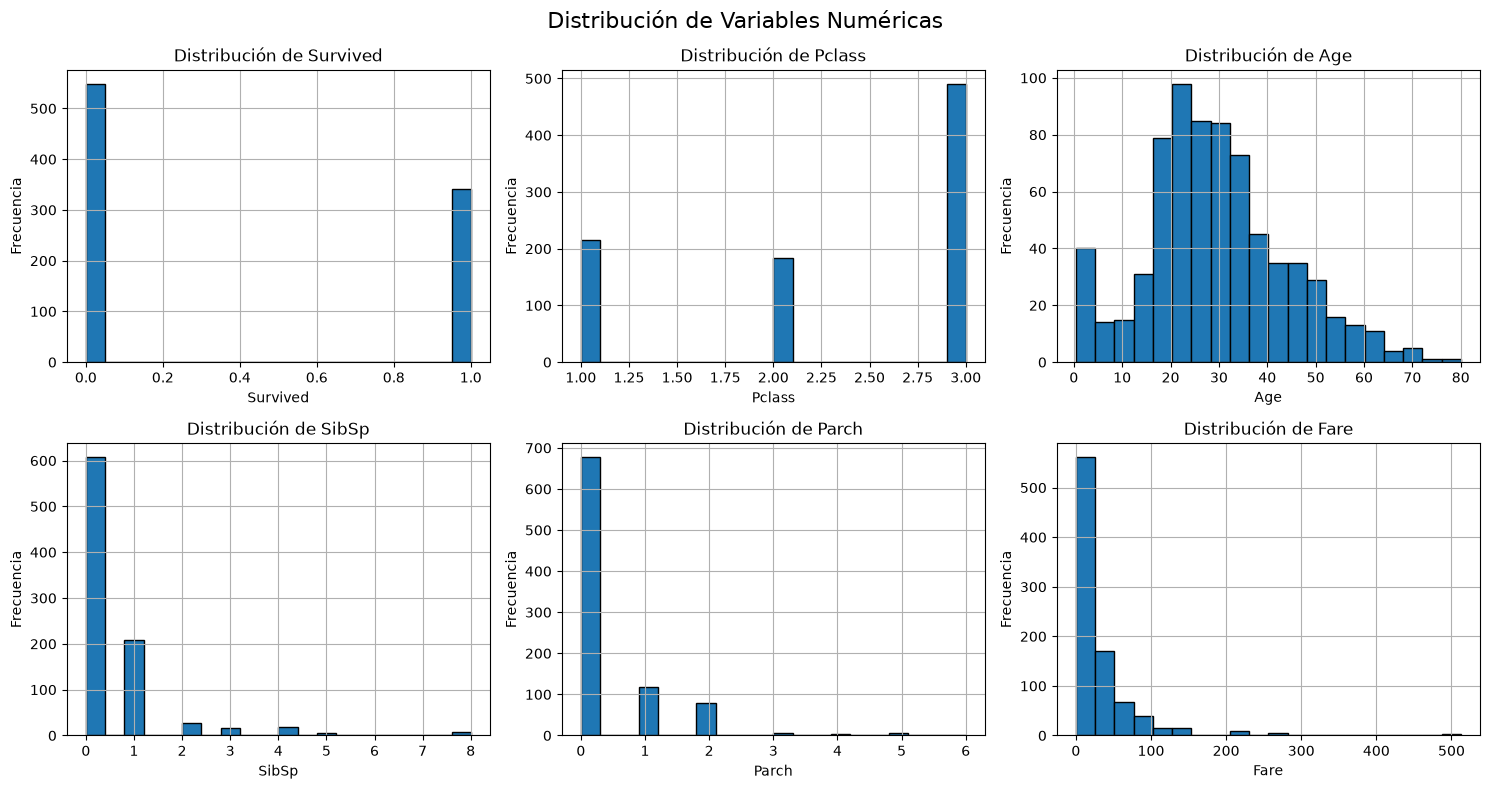

In [ ]:
# Crear la figura y los subplots
fig, axes = plt.subplots(nrows=rows, ncols=cols, figsize=(15, 8))
fig.suptitle('Distribución de Variables Numéricas', fontsize=16)

# Aplanar el array de ejes en caso de que sea 2D
axes = axes.flatten() if n > 3 else [axes]

# Crear histogramas para cada variable numérica
for i, col in enumerate(columnas_numericas):
    ax = axes[i]
    titanic_passengers[col].hist(ax=ax, bins=20, edgecolor='black')
    ax.set_title(f'Distribución de {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Frecuencia')

# Ocultar subplots vacíos si los hay
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [101]:
columnas_texto=titanic_passengers[['Sex','Embarked']]
nrows_texto=2
ncols_texto=1

In [68]:
print(titanic_passengers[columnas_texto[1]])

PassengerId
1        male
2      female
3      female
4      female
5        male
        ...  
887      male
888    female
889    female
890      male
891      male
Name: Sex, Length: 891, dtype: str


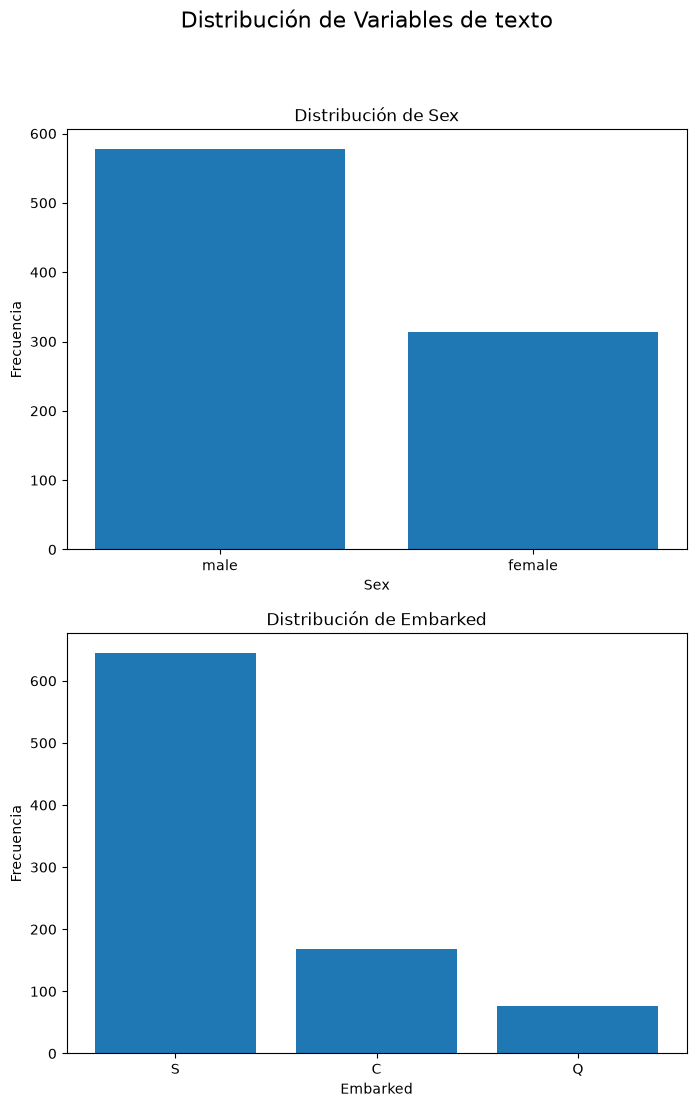

In [107]:
fig, axes = plt.subplots(nrows=nrows_texto, ncols=ncols_texto, figsize=(8, 12))
fig.suptitle('Distribución de Variables de texto', fontsize=16)
axes = axes.flatten()
for i,col in enumerate(columnas_texto):
    ax=axes[i]
    col_i=titanic_passengers[col].value_counts()
    ax.bar(col_i.index,col_i)
    ax.set_title(f'Distribución de {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Frecuencia')

In [128]:
tasa_supervivencia_sexo=titanic_passengers.groupby('Sex')['Survived'].mean().round(2)
display(tasa_supervivencia_sexo.head())

Sex
female    0.74
male      0.19
Name: Survived, dtype: float64

Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64

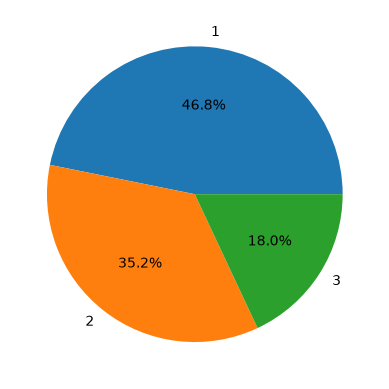

In [130]:
tasa_supervivencia_clase=titanic_passengers.groupby('Pclass')['Survived'].mean()
display(tasa_supervivencia_clase.head())
plt.pie(x=tasa_supervivencia_clase,labels=tasa_supervivencia_clase.index,autopct='%1.1f%%')

PassengerId
2      38.0
3      26.0
4      35.0
9      27.0
10     14.0
       ... 
876    15.0
880    56.0
881    25.0
888    19.0
890    26.0
Name: Age, Length: 342, dtype: float64

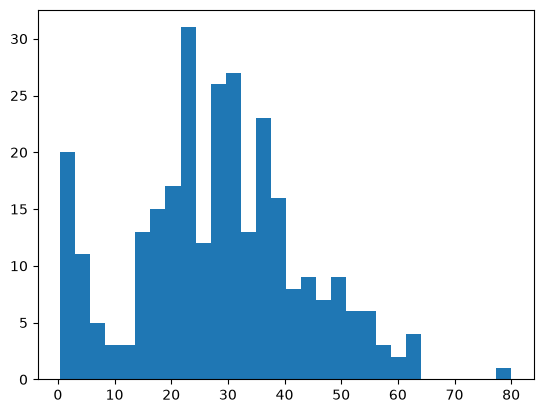

In [ ]:
edades_sobrevivientes=titanic_passengers[titanic_passengers['Survived']== 1]['Age']
display(edades_sobrevivientes)
plt.hist(edades_sobrevivientes,bins=30)
plt.show()

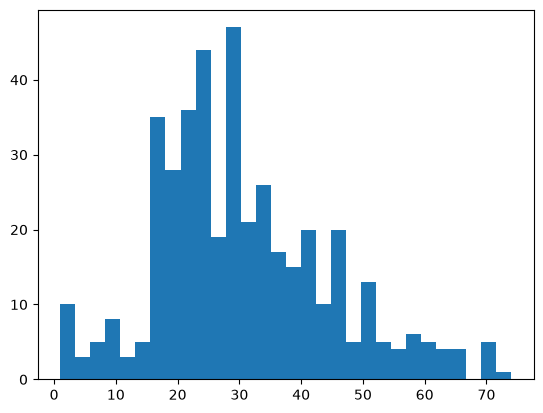

In [151]:
edades_no_sobrevivientes=titanic_passengers[titanic_passengers['Survived']== 0]['Age']
plt.hist(edades_no_sobrevivientes,bins=30)
plt.show()